# 01 · Data exploration — CIC-IDS-2017 (network domain)

**CIC-IDS-2017** contains 5 days of labelled network traffic (Monday = benign only, Tuesday–Friday = benign + attacks:
brute force, DoS/DDoS, web attacks, infiltration, botnet, port scan). Each row is a **bidirectional flow** described by
~80 statistics produced by CICFlowMeter.

The NIDS graph builder (`src/graph/cic_graph.py`) keeps **16 flow features**, applies `log1p`, and groups 500 consecutive flows into one graph (`window_size=500` in the orchestrator).
A window is labelled malicious if more than 30% of its flows are attacks.

What this notebook checks:
1. data quality (inf/NaN, duplicates, constant columns) — the dataset is known to need cleaning;
2. class imbalance, overall and per attack type and per day;
3. distributions and correlation of the 16 features the model actually uses.

In [1]:
import sys
import json
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # torch.jit / pandas deprecations
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.utils.config import CONFIG

EXP = project_root / CONFIG["experiments_path"]
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})
GNN_NAME = "GNN (MFGraph)"


def latest_run(base: Path, filename: str):
    """Most recent timestamped run folder under `base` that contains `filename`."""
    runs = sorted(p.parent for p in base.glob(f"*/{filename}")) if base.exists() else []
    return runs[-1] if runs else None


def missing(path, task):
    print(f"[Missing] {path}\nRun first:  python orchestrator.py -t {task}")

In [2]:
CIC_DIR = project_root / "data" / "raw" / "CIC-IDS-2017"
frames = []
for f in sorted(CIC_DIR.glob("*.csv")):
    df = pd.read_csv(f, skipinitialspace=True, low_memory=False)
    df["Day"] = f.name.split("-")[0]
    df["File"] = f.stem.replace(".pcap_ISCX", "")
    frames.append(df)
raw = pd.concat(frames, ignore_index=True)
raw.columns = raw.columns.str.strip()
print(f"{len(frames)} files, {len(raw):,} flows, {raw.shape[1] - 2} original columns")

8 files, 2,830,743 flows, 79 original columns


## 1. Data quality

In [3]:
num = raw.select_dtypes("number")
quality = {
    "rows with inf": int(np.isinf(num).any(axis=1).sum()),
    "rows with NaN": int(num.isna().any(axis=1).sum()),
    "duplicate rows": int(raw.duplicated().sum()),
    "constant columns": [c for c in num.columns if num[c].nunique() <= 1],
}
for k, v in quality.items():
    print(f"{k:>18}: {v}")

df_cic = raw.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
df_cic = df_cic.drop(columns=quality["constant columns"])
df_cic["Binary_Label"] = (df_cic["Label"] != "BENIGN").astype(int)
print(f"\nAfter cleaning: {len(df_cic):,} flows ({100 * len(df_cic) / len(raw):.1f}% kept)")

     rows with inf: 2867
     rows with NaN: 1358
    duplicate rows: 256479
  constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']



After cleaning: 2,572,640 flows (90.9% kept)


`Flow Bytes/s` and `Flow Packets/s` contain infinities (division by a zero duration), several columns are constant, and
there are many exact duplicates. `cic_graph.py` drops inf/NaN rows too; duplicates are kept there on purpose because
graph windows must preserve the original flow order.

## 2. Class distribution

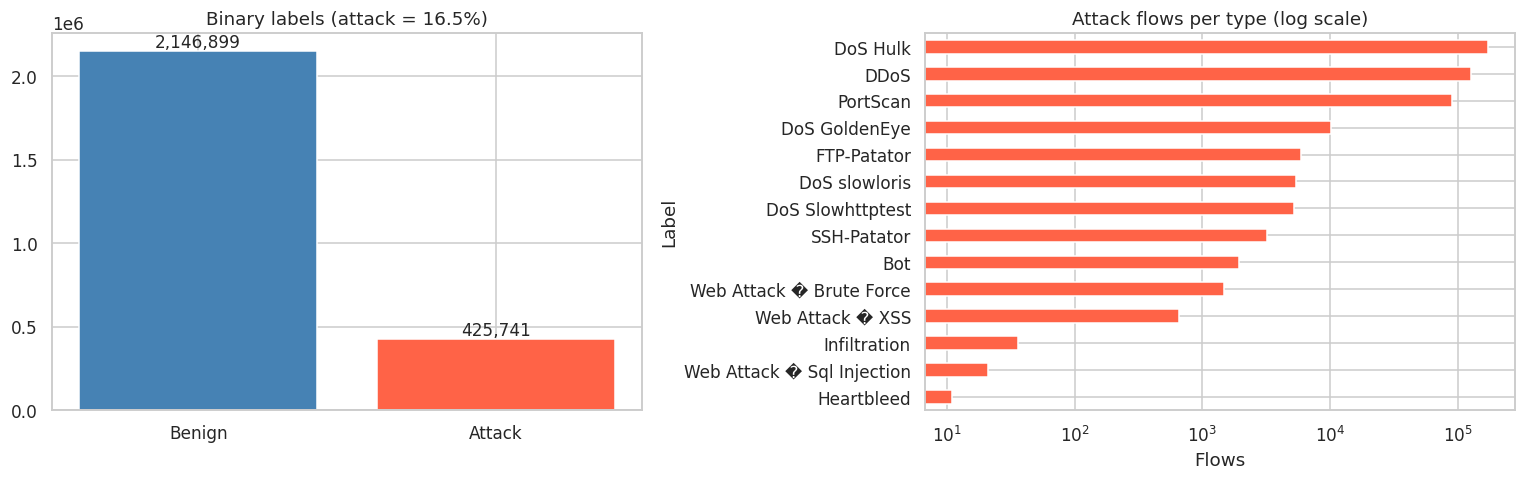

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
b = df_cic["Binary_Label"].value_counts().rename({0: "Benign", 1: "Attack"})
axes[0].bar(b.index, b.values, color=["steelblue", "tomato"])
axes[0].set_title(f"Binary labels (attack = {100 * b['Attack'] / b.sum():.1f}%)")
for i, v in enumerate(b.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

per_type = df_cic.loc[df_cic.Label != "BENIGN", "Label"].value_counts()
per_type.sort_values().plot(kind="barh", ax=axes[1], color="tomato", logx=True)
axes[1].set_title("Attack flows per type (log scale)"); axes[1].set_xlabel("Flows")
plt.tight_layout(); plt.show()

In [5]:
by_file = pd.crosstab(df_cic["File"], df_cic["Binary_Label"]).rename(columns={0: "Benign", 1: "Attack"})
by_file["attack %"] = (100 * by_file["Attack"] / by_file.sum(axis=1)).round(1)
display(by_file)

Binary_Label,Benign,Attack,attack %
File,,,
Friday-WorkingHours-Afternoon-DDos,95068,128014,57.4
Friday-WorkingHours-Afternoon-PortScan,123083,90694,42.4
Friday-WorkingHours-Morning,182096,1948,1.1
Monday-WorkingHours,502650,0,0.0
Thursday-WorkingHours-Afternoon-Infilteration,252754,36,0.0
Thursday-WorkingHours-Morning-WebAttacks,162036,2143,1.3
Tuesday-WorkingHours,412476,9150,2.2
Wednesday-workingHours,416736,193756,31.7


* Attacks are ~16% of the cleaned flows, but the per-type counts span **4 orders of magnitude** (DoS Hulk vs. Heartbleed / SQL injection).
  Rare classes are effectively invisible to a binary detector, which is why the project reports **F1 and recall** rather than accuracy.
* The attack share changes drastically by file (0% Monday, >50% in DDoS/PortScan afternoons). The NIDS split in
  `nids_dataset.py` is therefore done **chronologically within each file** (80/10/10), so every scenario is represented in train,
  validation and test, and the test windows are always *later* than the training ones.

## 3. The 16 features used by the NIDS graph

In [6]:
NIDS_FEATURES = [
    "Total Length of Fwd Packets", "Total Length of Bwd Packets", "Fwd Packet Length Mean",
    "Bwd Packet Length Mean", "Flow IAT Mean", "Fwd IAT Mean", "Bwd IAT Mean", "Flow Packets/s",
    "Flow Bytes/s", "FIN Flag Count", "SYN Flag Count", "ACK Flag Count", "Flow Duration",
    "Total Fwd Packets", "Total Backward Packets", "Fwd PSH Flags",
]
assert len(NIDS_FEATURES) == CONFIG["nids"]["input_dim"]

sample = df_cic.groupby("Binary_Label").sample(50_000, random_state=42)
X_log = np.log1p(sample[NIDS_FEATURES].clip(lower=0))
display(sample.groupby("Binary_Label")[NIDS_FEATURES].median().T.rename(columns={0: "Benign median", 1: "Attack median"}).round(2))

Binary_Label,Benign median,Attack median
Total Length of Fwd Packets,68.00,30.00
Total Length of Bwd Packets,142.00,11595.00
Fwd Packet Length Mean,38.00,8.67
Bwd Packet Length Mean,83.00,1656.43
Flow IAT Mean,15183.00,1056419.33
Fwd IAT Mean,4.00,1155161.46
Bwd IAT Mean,3.00,13240.20
Flow Packets/s,86.68,1.12
Flow Bytes/s,4453.87,143.24
FIN Flag Count,0.00,0.00


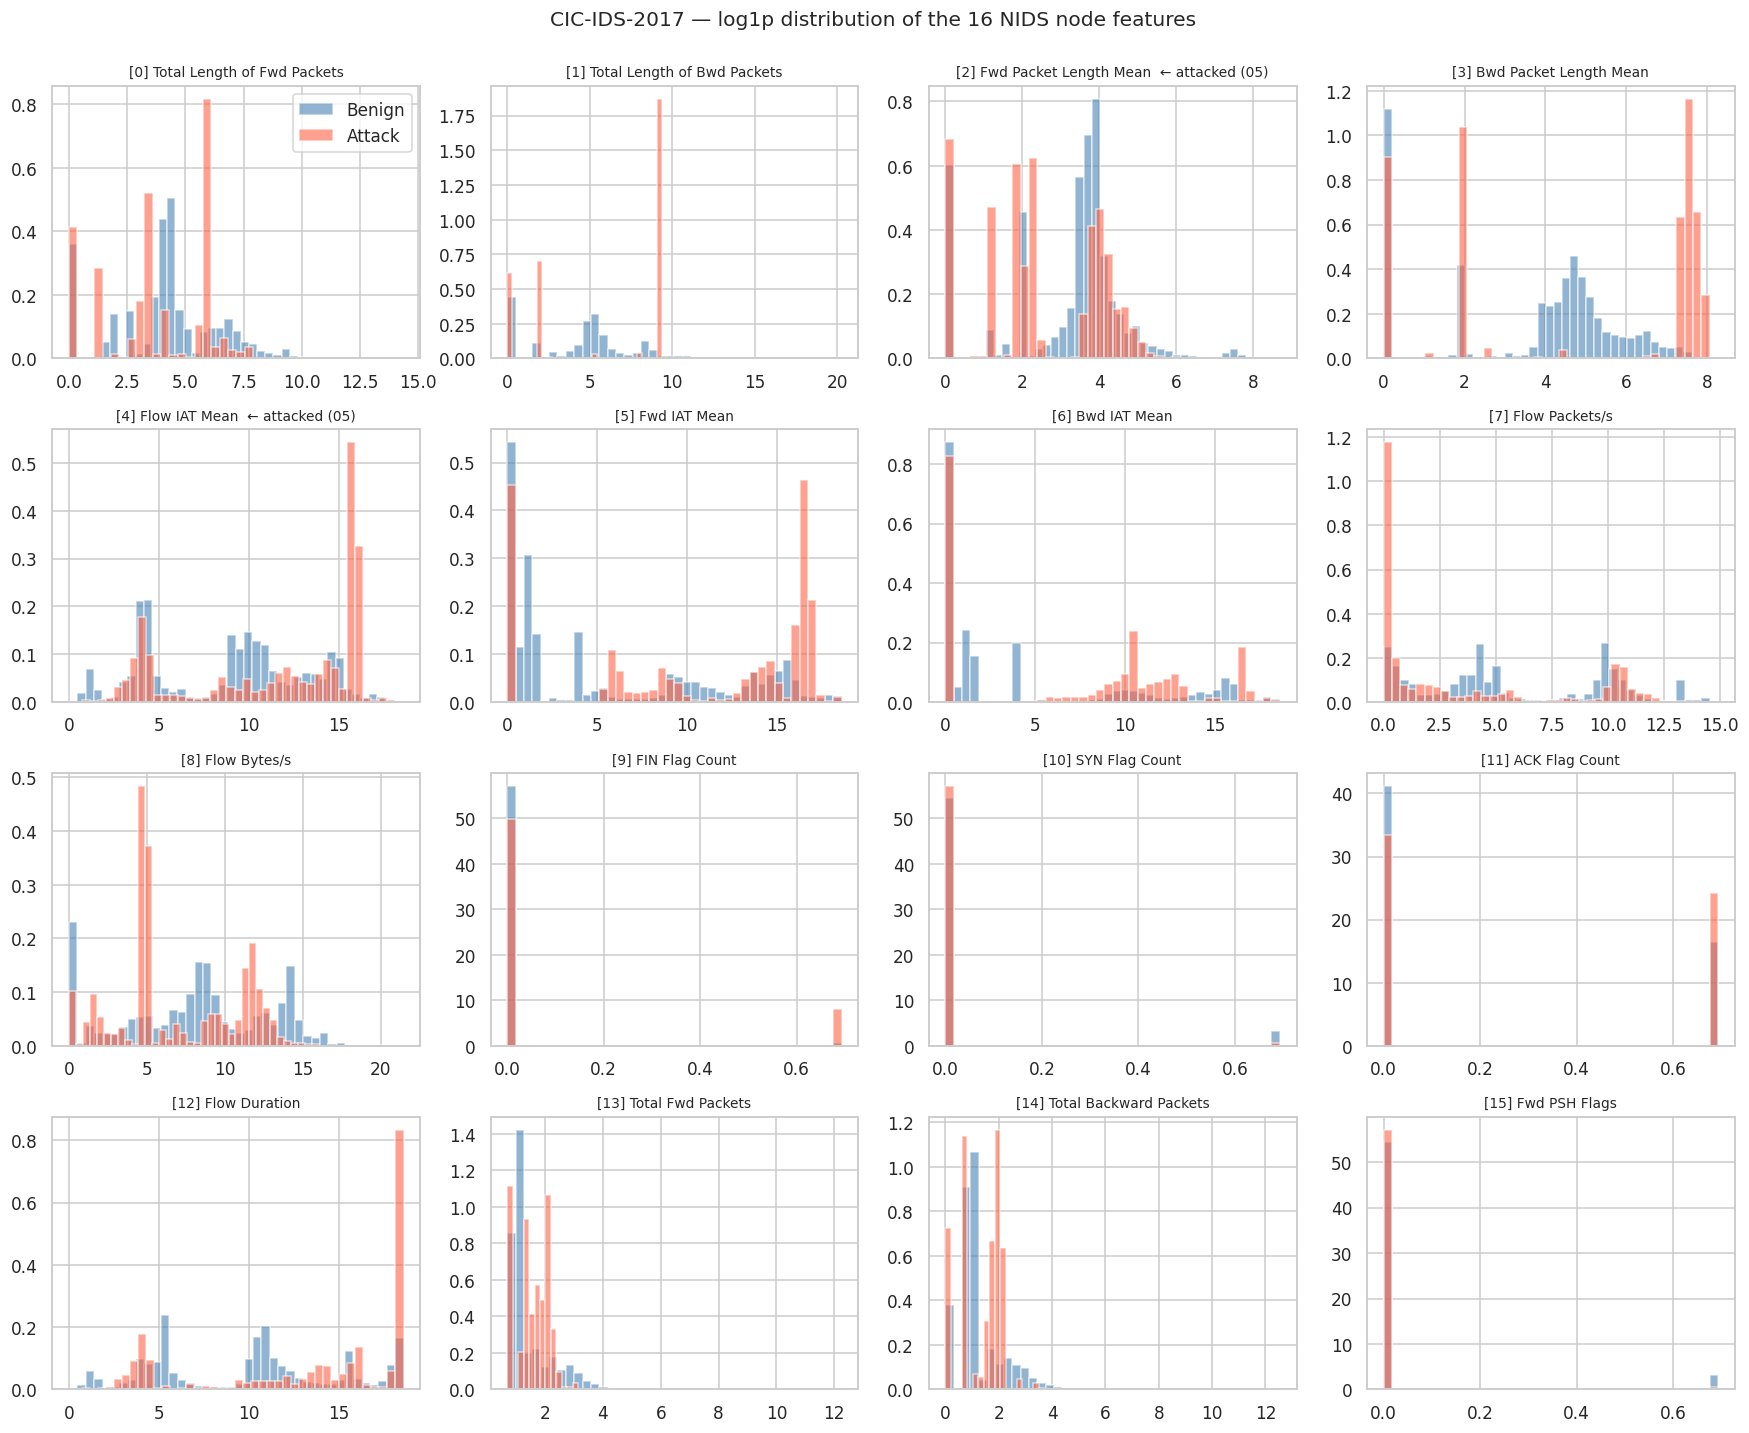

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for i, (ax, col) in enumerate(zip(axes.ravel(), NIDS_FEATURES)):
    for lbl, c, txt in [(0, "steelblue", "Benign"), (1, "tomato", "Attack")]:
        ax.hist(X_log.loc[sample.Binary_Label == lbl, col], bins=40, alpha=0.6, density=True, color=c, label=txt)
    marker = "  ← attacked (05)" if i in (2, 4) else ""
    ax.set_title(f"[{i}] {col}{marker}", fontsize=9)
axes[0, 0].legend()
plt.suptitle("CIC-IDS-2017 — log1p distribution of the 16 NIDS node features", y=1.0)
plt.tight_layout(); plt.show()

Features **[2] Fwd Packet Length Mean** and **[4] Flow IAT Mean** are the ones scaled by the adversarial attacks in
notebook 05 (packet padding and timing manipulation). Both are clearly bimodal and class-dependent, so an attacker who
moves them is moving *useful* signal, not noise.

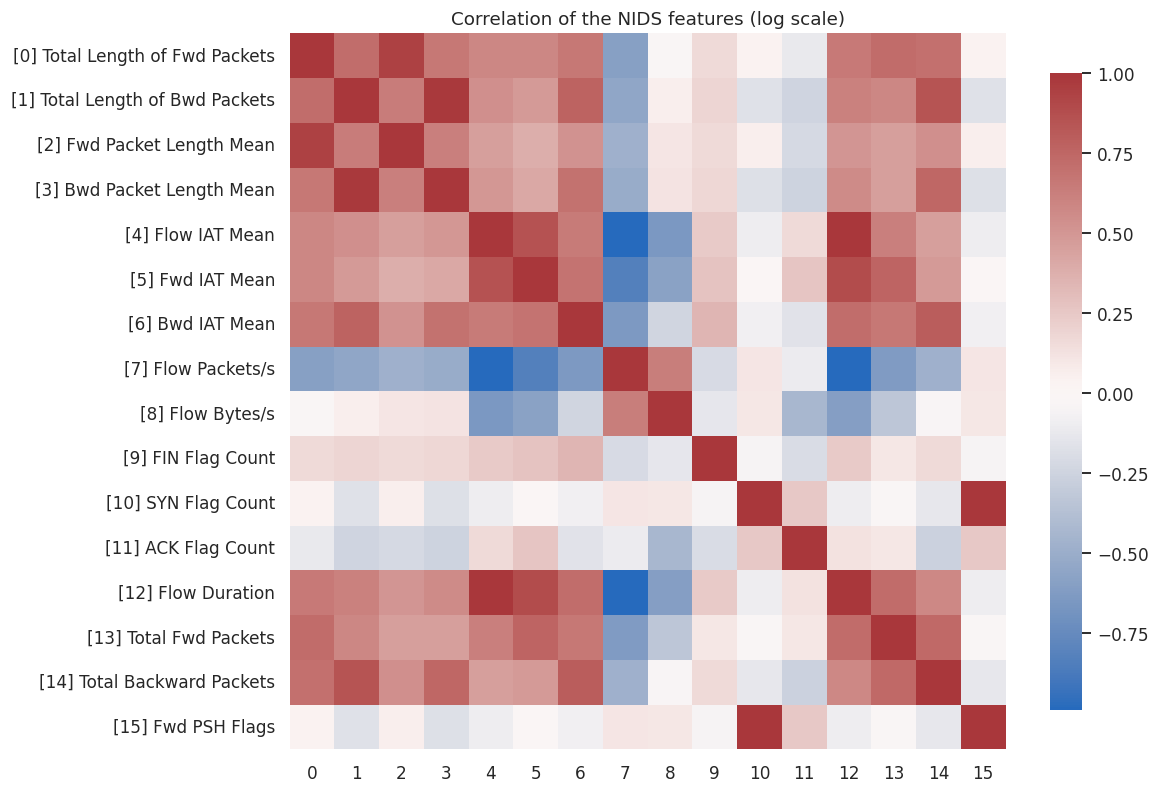

In [8]:
corr = X_log.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.7},
            xticklabels=range(len(NIDS_FEATURES)), yticklabels=[f"[{i}] {c}" for i, c in enumerate(NIDS_FEATURES)])
plt.title("Correlation of the NIDS features (log scale)"); plt.tight_layout(); plt.show()

**Takeaways**
* Several features are strongly correlated (forward/backward lengths, IAT means), so perturbing one feature may be partly
  compensated by its correlated neighbours — but only for models that look at more than one feature at a time.
* The graph adds information a flat model lacks: *which* flows share an IP, port, or temporal neighbourhood (notebook 02).